# Integração e Cenários Energéticos até 2036

Projeto: **O Impacto dos Data Centers na Demanda Elétrica Brasileira até 2036: Uma Análise com Dados do ONS, ANEEL e EPE**.

**Pergunta central:** Qual será a dimensão do crescimento da demanda elétrica dos data centers até 2036 e como esse crescimento se relaciona com a infraestrutura de geração brasileira?

As projeções EPE são comparadas com a série histórica ONS e o cadastro ANEEL, sem inferir adequação do sistema. O recorte EPE é de data centers de grande porte e não exclusivamente IA.


## 1. Dados de Referência da EPE

Validação dos indicadores de consumo elétrico e demanda dos data centers utilizados na análise de cenários.

In [1]:

from pathlib import Path
import pandas as pd

# Identificar a raiz do projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar os dados da EPE
ARQUIVO_EPE = (
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

if not ARQUIVO_EPE.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_EPE}"
    )

df_epe = pd.read_csv(ARQUIVO_EPE)

print("=== DADOS EPE — PDE 2036 ===")

print("\nDimensões:")
print(df_epe.shape)

print("\nColunas:")
print(df_epe.columns.tolist())

print("\nTipos:")
print(df_epe.dtypes)

print("\nDados disponíveis:")
display(df_epe)

print("\nValores ausentes:")
display(df_epe.isna().sum())


=== DADOS EPE — PDE 2036 ===

Dimensões:
(4, 20)

Colunas:
['ano', 'indicador', 'valor_twh', 'natureza', 'fonte', 'url_fonte', 'cenario', 'versao', 'documento', 'url_documento', 'versao_documento', 'pagina_impressa', 'figura_tabela', 'definicao', 'perimetro', 'documento_complementar', 'url_documento_complementar', 'versao_documento_complementar', 'pagina_impressa_complementar', 'data_verificacao_referencias']

Tipos:
ano                              int64
indicador                          str
valor_twh                        int64
natureza                           str
fonte                              str
url_fonte                          str
cenario                            str
versao                             str
documento                          str
url_documento                      str
versao_documento                   str
pagina_impressa                  int64
figura_tabela                      str
definicao                          str
perimetro                        

,ano,indicador,valor_twh,natureza,fonte,url_fonte,cenario,versao,documento,url_documento,versao_documento,pagina_impressa,figura_tabela,definicao,perimetro,documento_complementar,url_documento_complementar,versao_documento_complementar,pagina_impressa_complementar,data_verificacao_referencias
0,2026,data_centers,3,estimativa,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,60,Figura 2-12,Consumo anual de eletricidade dos data centers...,Data centers de grande porte abrangidos pelo e...,PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,36,2026-11-10
1,2036,data_centers,30,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,60,Figura 2-12,Consumo anual de eletricidade dos data centers...,Data centers de grande porte abrangidos pelo e...,PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,36,2026-11-10
2,2026,eletricidade_total,702,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,59,Tabela 2-4,Consumo anual total de eletricidade no Brasil,"Classes de consumo, autoprodução não injetada ...",PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,11,2026-11-10
3,2036,eletricidade_total,979,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,59,Tabela 2-4,Consumo anual total de eletricidade no Brasil,"Classes de consumo, autoprodução não injetada ...",PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,11,2026-11-10



Valores ausentes:


ano                              0
indicador                        0
valor_twh                        0
natureza                         0
fonte                            0
url_fonte                        0
cenario                          0
versao                           0
documento                        0
url_documento                    0
versao_documento                 0
pagina_impressa                  0
figura_tabela                    0
definicao                        0
perimetro                        0
documento_complementar           0
url_documento_complementar       0
versao_documento_complementar    0
pagina_impressa_complementar     0
data_verificacao_referencias     0
dtype: int64

## 2. Visualização 18 - Demanda dos Data Centers até 2036
Comparação do consumo anual projetado e da participação dos data centers no consumo total de eletricidade.

=== INDICADORES EPE ===


indicador,ano,data_centers,eletricidade_total,participacao_pct
0,2026,3,702,0.427
1,2036,30,979,3.064


Crescimento data centers: 900.0%
Crescimento total: 39.5%


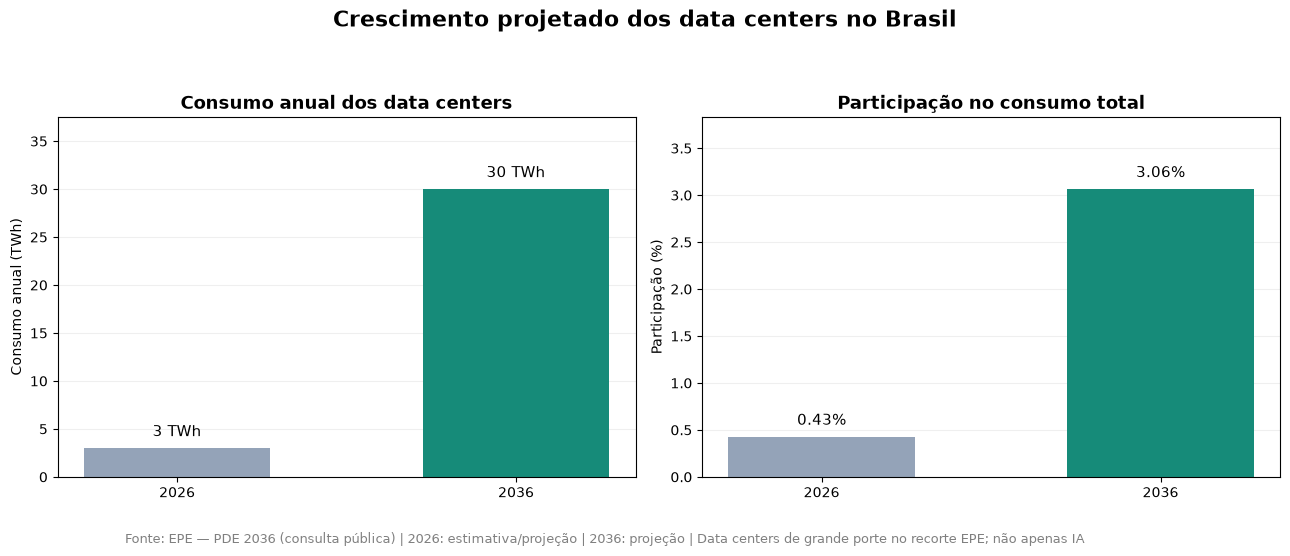

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. CONFIGURAÇÕES
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO_EPE = (
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)

# 2. CARREGAR E VALIDAR
df_epe = pd.read_csv(ARQUIVO_EPE)

colunas_necessarias = {
    "ano", "indicador", "valor_twh", "natureza"
}

if not colunas_necessarias.issubset(df_epe.columns):
    raise ValueError("Colunas obrigatórias ausentes.")

if df_epe.duplicated(["ano", "indicador"]).any():
    raise ValueError("Indicadores duplicados por ano.")

# Transformar indicadores em colunas
df_cenarios = (
    df_epe.pivot(
        index="ano",
        columns="indicador",
        values="valor_twh"
    )
    .reset_index()
    .sort_values("ano")
)

esperados = {"data_centers", "eletricidade_total"}

if not esperados.issubset(df_cenarios.columns):
    raise ValueError("Indicadores esperados não encontrados.")

if set(df_cenarios["ano"]) != {2026, 2036}:
    raise ValueError("Anos de referência inesperados.")

if (
    df_cenarios[
        ["data_centers", "eletricidade_total"]
    ].isna().any().any()
):
    raise ValueError("Valores ausentes nos indicadores.")

# 3. CALCULAR INDICADORES
df_cenarios["participacao_pct"] = (
    df_cenarios["data_centers"]
    / df_cenarios["eletricidade_total"]
    * 100
)

base = df_cenarios.set_index("ano")

dc_2026 = base.loc[2026, "data_centers"]
dc_2036 = base.loc[2036, "data_centers"]

total_2026 = base.loc[2026, "eletricidade_total"]
total_2036 = base.loc[2036, "eletricidade_total"]

crescimento_dc = (
    (dc_2036 / dc_2026 - 1) * 100
)

crescimento_total = (
    (total_2036 / total_2026 - 1) * 100
)

print("=== INDICADORES EPE ===")
display(df_cenarios.round(3))

print(f"Crescimento data centers: {crescimento_dc:.1f}%")
print(f"Crescimento total: {crescimento_total:.1f}%")

# 4. GRÁFICO 18
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13, 5.5)
)

anos = df_cenarios["ano"].astype(str)

# Painel 1 — Consumo anual
barras1 = ax1.bar(
    anos,
    df_cenarios["data_centers"],
    color=["#94A3B8", "#168B79"],
    width=0.55
)

ax1.bar_label(
    barras1,
    labels=[
        f"{v:.0f} TWh"
        for v in df_cenarios["data_centers"]
    ],
    padding=6,
    fontsize=11
)

ax1.set_title(
    "Consumo anual dos data centers",
    fontsize=13,
    fontweight="bold"
)

ax1.set_ylabel("Consumo anual (TWh)")
ax1.set_ylim(0, dc_2036 * 1.25)
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)

# Painel 2 — Participação
barras2 = ax2.bar(
    anos,
    df_cenarios["participacao_pct"],
    color=["#94A3B8", "#168B79"],
    width=0.55
)

ax2.bar_label(
    barras2,
    labels=[
        f"{v:.2f}%"
        for v in df_cenarios["participacao_pct"]
    ],
    padding=6,
    fontsize=11
)

ax2.set_title(
    "Participação no consumo total",
    fontsize=13,
    fontweight="bold"
)

ax2.set_ylabel("Participação (%)")
ax2.set_ylim(
    0,
    df_cenarios["participacao_pct"].max() * 1.25
)

ax2.grid(axis="y", alpha=0.2)
ax2.set_axisbelow(True)

fig.suptitle(
    "Crescimento projetado dos data centers no Brasil",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.10, 0.01,
    "Fonte: EPE — PDE 2036 (consulta pública) | "
    "2026: estimativa/projeção | 2036: projeção | "
    "Data centers de grande porte no recorte EPE; não apenas IA",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.92])

plt.savefig(
    PASTA_IMAGENS / "18_projecao_datacenters_2036.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3. Visualização 19 - Potência Média dos Data Centers

Conversão das projeções anuais de consumo da EPE em potência média equivalente, considerando as horas de cada ano.

,ano,valor_twh,horas_ano,potencia_media_gw,potencia_media_mw
0,2026,3,8760,0.342,342.466
1,2036,30,8784,3.415,3415.301



Aumento da potência média equivalente: 3.073 GW


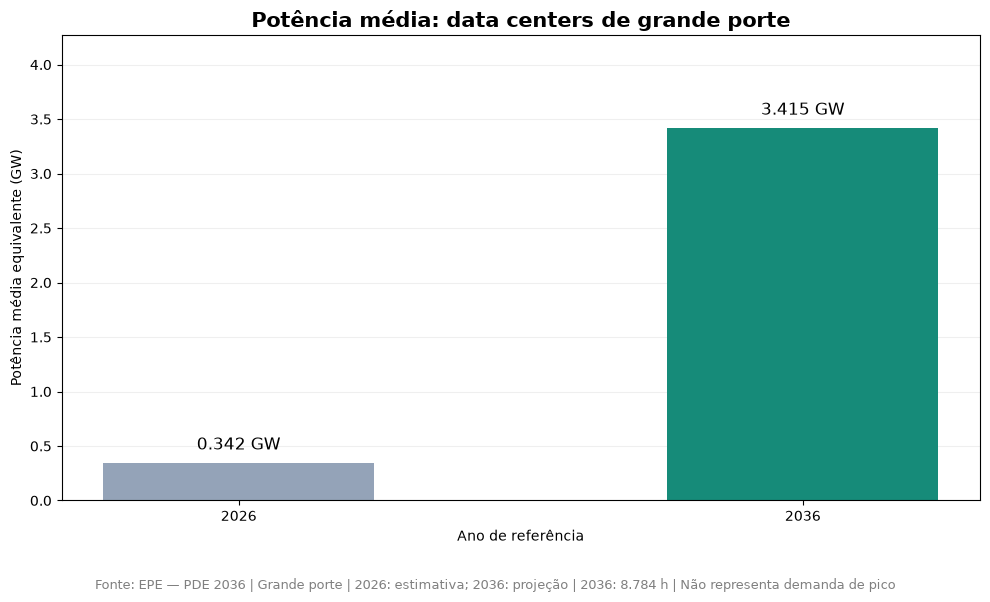

In [3]:

import calendar
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# 1. CONFIGURAÇÕES

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO_EPE = (
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)

# 2. CARREGAR AS PROJEÇÕES
df_epe = pd.read_csv(ARQUIVO_EPE)

df_dc = df_epe[
    df_epe["indicador"] == "data_centers"
].copy()

df_dc = df_dc.sort_values("ano")

if set(df_dc["ano"]) != {2026, 2036}:
    raise ValueError(
        "Anos de referência inesperados."
    )

if df_dc["ano"].duplicated().any():
    raise ValueError("Anos duplicados.")

if (
    df_dc["valor_twh"].isna().any()
    or df_dc["valor_twh"].lt(0).any()
):
    raise ValueError("Valores inválidos.")

# 3. CONVERSÃO DE ENERGIA EM POTÊNCIA
def horas_do_ano(ano):
    return 8784 if calendar.isleap(int(ano)) else 8760


df_dc["horas_ano"] = (
    df_dc["ano"].apply(horas_do_ano)
)

# 1 TWh = 1.000 GWh
# Potência média GW = GWh / horas
df_dc["potencia_media_gw"] = (
    df_dc["valor_twh"] * 1000
    / df_dc["horas_ano"]
)

df_dc["potencia_media_mw"] = (
    df_dc["potencia_media_gw"] * 1000
)

display(
    df_dc[
        [
            "ano",
            "valor_twh",
            "horas_ano",
            "potencia_media_gw",
            "potencia_media_mw"
        ]
    ].round(3)
)

potencias = df_dc.set_index("ano")[
    "potencia_media_gw"
]

incremento_gw = (
    potencias.loc[2036] - potencias.loc[2026]
)

print(
    f"\nAumento da potência média equivalente: "
    f"{incremento_gw:.3f} GW"
)

# 4. VISUALIZAÇÃO
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.bar(
    df_dc["ano"].astype(str),
    df_dc["potencia_media_gw"],
    color=["#94A3B8", "#168B79"],
    width=0.48
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.3f} GW"
        for valor in df_dc["potencia_media_gw"]
    ],
    padding=7,
    fontsize=12
)

ax.set_title(
    "Potência média: data centers de grande porte",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Potência média equivalente (GW)")
ax.set_xlabel("Ano de referência")

ax.set_ylim(
    0,
    df_dc["potencia_media_gw"].max() * 1.25
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.10, 0.01,
    "Fonte: EPE — PDE 2036 | "
    "Grande porte | 2026: estimativa; 2036: projeção | 2036: 8.784 h | "
    "Não representa demanda de pico",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    PASTA_IMAGENS /
    "19_potencia_media_datacenters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 4. Visualização 20 - Participação no Crescimento da Demanda

Comparação entre o aumento projetado do consumo dos data centers e o aumento total do consumo brasileiro de eletricidade entre 2026 e 2036.

=== CRESCIMENTO PROJETADO ===
Total: 277 TWh
Data centers: 27 TWh
Demais consumos: 250 TWh


,grupo,incremento_twh,participacao_pct
0,Data centers,27,9.75
1,Demais consumos,250,90.25


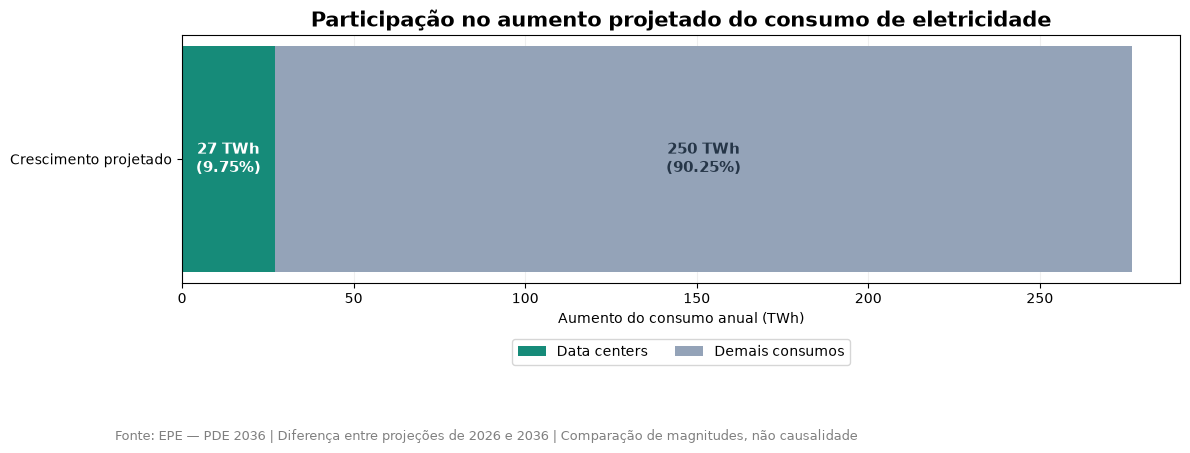

In [4]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 1. CONFIGURAÇÕES
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO_EPE = (
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)

# 2. CARREGAR E VALIDAR
df_epe = pd.read_csv(ARQUIVO_EPE)

if df_epe.duplicated(["ano", "indicador"]).any():
    raise ValueError("Indicadores duplicados.")

df = df_epe.pivot(
    index="ano",
    columns="indicador",
    values="valor_twh"
)

colunas = ["data_centers", "eletricidade_total"]

if (
    not {2026, 2036}.issubset(df.index)
    or not set(colunas).issubset(df.columns)
):
    raise ValueError(
        "Dados de referência incompletos."
    )

df = df.loc[[2026, 2036], colunas]

if df.isna().any().any():
    raise ValueError("Existem valores ausentes.")

# 3. CALCULAR O CRESCIMENTO
incremento_total = (
    df.loc[2036, "eletricidade_total"]
    - df.loc[2026, "eletricidade_total"]
)

incremento_dc = (
    df.loc[2036, "data_centers"]
    - df.loc[2026, "data_centers"]
)

incremento_demais = (
    incremento_total - incremento_dc
)

if (
    incremento_total <= 0
    or incremento_dc < 0
    or incremento_demais < 0
):
    raise ValueError(
        "Incrementos incompatíveis com o gráfico."
    )

participacao_dc = (
    incremento_dc / incremento_total * 100
)

participacao_demais = (
    incremento_demais / incremento_total * 100
)

resumo = pd.DataFrame({
    "grupo": [
        "Data centers",
        "Demais consumos"
    ],
    "incremento_twh": [
        incremento_dc,
        incremento_demais
    ],
    "participacao_pct": [
        participacao_dc,
        participacao_demais
    ]
})

print("=== CRESCIMENTO PROJETADO ===")
print(f"Total: {incremento_total:.0f} TWh")
print(f"Data centers: {incremento_dc:.0f} TWh")
print(f"Demais consumos: {incremento_demais:.0f} TWh")

display(resumo.round(2))

# 4. VISUALIZAÇÃO 20
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.barh(
    ["Crescimento projetado"],
    [incremento_dc],
    color="#168B79",
    label="Data centers",
    height=0.42
)

ax.barh(
    ["Crescimento projetado"],
    [incremento_demais],
    left=[incremento_dc],
    color="#94A3B8",
    label="Demais consumos",
    height=0.42
)

ax.text(
    incremento_dc / 2,
    0,
    f"{incremento_dc:.0f} TWh\n"
    f"({participacao_dc:.2f}%)",
    ha="center",
    va="center",
    fontsize=11,
    color="white",
    fontweight="bold"
)

ax.text(
    incremento_dc + incremento_demais / 2,
    0,
    f"{incremento_demais:.0f} TWh\n"
    f"({participacao_demais:.2f}%)",
    ha="center",
    va="center",
    fontsize=11,
    color="#263648",
    fontweight="bold"
)

ax.set_xlim(0, incremento_total * 1.05)

ax.set_title(
    "Participação no aumento projetado "
    "do consumo de eletricidade",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Aumento do consumo anual (TWh)")
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=2
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.10, 0.01,
    "Fonte: EPE — PDE 2036 | "
    "Diferença entre projeções de 2026 e 2036 | "
    "Comparação de magnitudes, não causalidade",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

plt.savefig(
    PASTA_IMAGENS /
    "20_participacao_crescimento_demanda.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Visualização 21 - Cenários de Demanda em 2036

Análise de sensibilidade do consumo dos data centers em três cenários, mantendo constante a demanda projetada dos demais consumidores.

=== CENÁRIOS DE DEMANDA — 2036 ===


,cenario,consumo_dc_twh,natureza,demais_consumos_twh,consumo_total_twh,participacao_dc_pct,potencia_media_dc_gw
0,Baixa demanda,15.0,Hipótese ilustrativa,949.0,964.0,1.556,1.708
1,Referência EPE,30.0,Referência EPE,949.0,979.0,3.064,3.415
2,Alta demanda,45.0,Hipótese ilustrativa,949.0,994.0,4.527,5.123


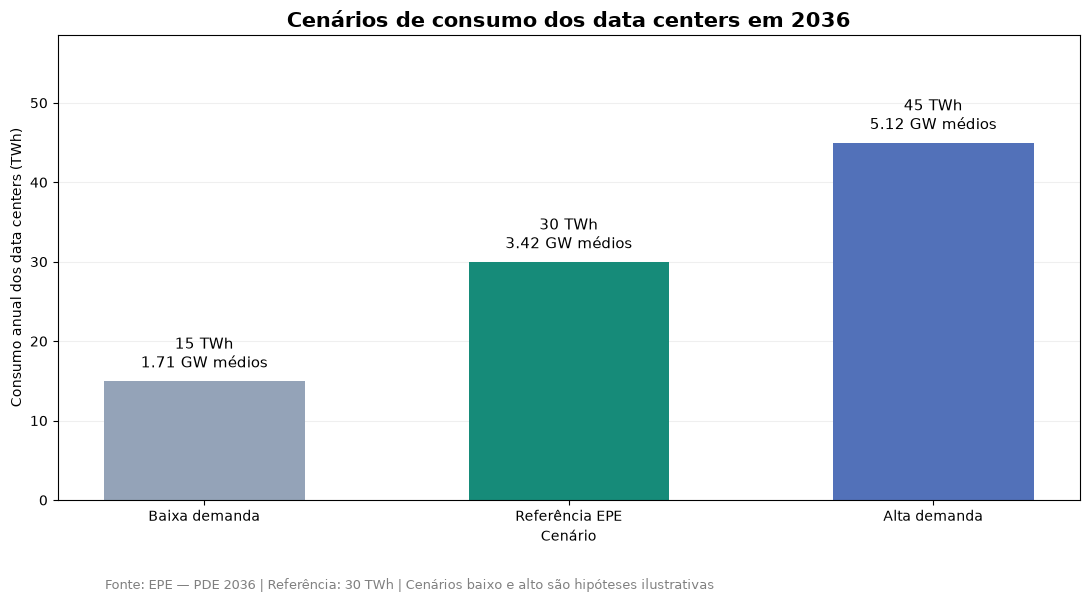

In [5]:

from pathlib import Path
import calendar
import pandas as pd
import matplotlib.pyplot as plt

# 1. CONFIGURAÇÕES
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO_EPE = (
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)

# 2. DADOS DE REFERÊNCIA DA EPE
epe = pd.read_csv(ARQUIVO_EPE)

if epe.duplicated(["ano", "indicador"]).any():
    raise ValueError("Indicadores duplicados.")

referencia = epe.pivot(
    index="ano",
    columns="indicador",
    values="valor_twh"
)

consumo_total_epe = float(
    referencia.loc[2036, "eletricidade_total"]
)

consumo_dc_epe = float(
    referencia.loc[2036, "data_centers"]
)

demais_consumos = (
    consumo_total_epe - consumo_dc_epe
)

if demais_consumos <= 0:
    raise ValueError("Referência inválida.")


# 3. CONSTRUIR CENÁRIOS
cenarios = pd.DataFrame({
    "cenario": [
        "Baixa demanda",
        "Referência EPE",
        "Alta demanda"
    ],
    "consumo_dc_twh": [
        consumo_dc_epe * 0.5,
        consumo_dc_epe,
        consumo_dc_epe * 1.5
    ],
    "natureza": [
        "Hipótese ilustrativa",
        "Referência EPE",
        "Hipótese ilustrativa"
    ]
})

cenarios["demais_consumos_twh"] = (
    demais_consumos
)

cenarios["consumo_total_twh"] = (
    cenarios["demais_consumos_twh"]
    + cenarios["consumo_dc_twh"]
)

cenarios["participacao_dc_pct"] = (
    cenarios["consumo_dc_twh"]
    / cenarios["consumo_total_twh"] * 100
)

horas_2036 = (
    8784 if calendar.isleap(2036) else 8760
)

cenarios["potencia_media_dc_gw"] = (
    cenarios["consumo_dc_twh"] * 1000
    / horas_2036
)

print("=== CENÁRIOS DE DEMANDA — 2036 ===")
display(cenarios.round(3))


# 4. GRÁFICO 21


fig, ax = plt.subplots(figsize=(11, 6))

cores = [
    "#94A3B8",
    "#168B79",
    "#5271B9"
]

barras = ax.bar(
    cenarios["cenario"],
    cenarios["consumo_dc_twh"],
    color=cores,
    width=0.55
)

ax.bar_label(
    barras,
    labels=[
        f"{energia:.0f} TWh\n"
        f"{potencia:.2f} GW médios"
        for energia, potencia in zip(
            cenarios["consumo_dc_twh"],
            cenarios["potencia_media_dc_gw"]
        )
    ],
    padding=6,
    fontsize=11
)

ax.set_title(
    "Cenários de consumo dos data centers em 2036",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Consumo anual dos data centers (TWh)")
ax.set_xlabel("Cenário")

ax.set_ylim(
    0,
    cenarios["consumo_dc_twh"].max() * 1.3
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.10, 0.01,
    "Fonte: EPE — PDE 2036 | Referência: 30 TWh | "
    "Cenários baixo e alto são hipóteses ilustrativas",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    PASTA_IMAGENS /
    "21_cenarios_demanda_2036.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Síntese das Evidências

A carga histórica do ONS combina dados operacionais e componentes estimados; a capacidade ANEEL é cadastral e a EPE traz estimativas e projeções. A participação de 3,06% usa o consumo total de eletricidade da EPE, não a carga do SIN.

Contém informações do [SIGA — ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel), disponibilizadas sob a [Open Database License (ODbL)](https://opendatacommons.org/licenses/odbl/1-0/). Os dados foram validados, deduplicados e agregados por este projeto.


In [6]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Dados de referência da EPE
epe = pd.read_csv(
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

epe_ref = epe.pivot(
    index="ano",
    columns="indicador",
    values="valor_twh"
)

# Dados da ANEEL: capacidade em operação
fontes_aneel = pd.read_parquet(
    BASE_DIR / "data/gold/aneel/capacidade_por_fonte.parquet"
)

capacidade_operacao_gw = (
    fontes_aneel["potencia_mw"].sum() / 1000
)

# Dados da carga ONS
carga = pd.read_parquet(
    BASE_DIR / "data/silver/carga_energia.parquet"
)

carga["data"] = pd.to_datetime(carga["data"])

# Somente janeiro a outubro de 2026
carga_2026 = carga[
    (carga["data"] >= "2026-01-01")
    & (carga["data"] < "2026-11-01")
].copy()

carga_diaria = (
    carga_2026.groupby("data")
    .agg(
        energia_mwh=("energia_mwh", "sum"),
        subsistemas=("id_subsistema", "nunique")
    )
)

if (
    carga_diaria.empty
    or not carga_diaria["subsistemas"].eq(4).all()
    or len(carga_diaria) != 304
):
    raise ValueError(
        "Carga incompleta de janeiro a outubro de 2026."
    )

carga_media_gw = (
    carga_diaria["energia_mwh"].sum()
    / (len(carga_diaria) * 24)
    / 1000
)

dc_2036 = float(
    epe_ref.loc[2036, "data_centers"]
)

total_2036 = float(
    epe_ref.loc[2036, "eletricidade_total"]
)

resumo = pd.DataFrame([
    {
        "fonte": "ONS",
        "indicador": "Carga média jan-out/2026",
        "valor": round(carga_media_gw, 2),
        "unidade": "GWmed",
        "natureza": "Histórico ONS com estimativas"
    },
    {
        "fonte": "ANEEL",
        "indicador": "Capacidade fiscalizada em operação",
        "valor": round(capacidade_operacao_gw, 2),
        "unidade": "GW",
        "natureza": "Cadastro de nov/2026"
    },
    {
        "fonte": "EPE",
        "indicador": "Consumo dos data centers em 2036",
        "valor": dc_2036,
        "unidade": "TWh/ano",
        "natureza": "Projeção"
    },
    {
        "fonte": "EPE",
        "indicador": "Consumo total em 2036",
        "valor": total_2036,
        "unidade": "TWh/ano",
        "natureza": "Projeção"
    },
    {
        "fonte": "EPE",
        "indicador": "Participação dos data centers em 2036",
        "valor": round(dc_2036 / total_2036 * 100, 2),
        "unidade": "%",
        "natureza": "Indicador calculado"
    }
])

display(resumo)

import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.publicacao import Publicacao

destino = BASE_DIR / "data/gold/sintese_2036.csv"
with Publicacao(BASE_DIR, "sintese_2036") as publicacao:
    relativo = "data/gold/sintese_2036.csv"
    staging = publicacao.caminho(relativo)
    resumo.to_csv(staging, index=False, encoding="utf-8-sig")
    validado = pd.read_csv(staging)
    try:
        pd.testing.assert_frame_equal(validado, resumo, check_dtype=False, check_exact=True)
    except AssertionError as erro:
        raise ValueError("Sintese gravada e inconsistente.") from erro
    publicacao.confirmar([relativo], {"registros": len(resumo)})

print(f"\nSíntese salva em: {destino.relative_to(BASE_DIR).as_posix()}")


,fonte,indicador,valor,unidade,natureza
0,ONS,Carga média jan-out/2026,80.80,GWmed,Histórico ONS com estimativas
1,ANEEL,Capacidade fiscalizada em operação,221.56,GW,Cadastro de nov/2026
2,EPE,Consumo dos data centers em 2036,30.00,TWh/ano,Projeção
3,EPE,Consumo total em 2036,979.00,TWh/ano,Projeção
4,EPE,Participação dos data centers em 2036,3.06,%,Indicador calculado



Síntese salva em: data/gold/sintese_2036.csv


## 7. Conclusão Técnica

No cenário de referência da EPE, o consumo anual dos data centers de grande porte do recorte passa de **3 TWh em 2026 para 30 TWh em 2036**: acréscimo de **27 TWh/ano**, ou **900%**. Em 2036, isso equivale a **3,4153 GWmed** usando as 8.784 horas do ano civil e a **3,06%** dos 979 TWh de consumo total projetado pela EPE. A EPE também utiliza a convenção de 8.760 horas em determinados contextos; ela não é o cálculo civil adotado aqui.

O crescimento de 27 TWh corresponde a **9,75%** do aumento de 277 TWh/ano projetado para o consumo total, comparação aritmética, sem atribuição causal. A carga média histórica do SIN em jan–out/2026 foi **80,80 GWmed**, com componentes estimados e perímetro distinto do consumo total da EPE. A fotografia ANEEL de 09/11/2026 registra **221,56 GW** de potência fiscalizada em operação e **93,48 GW** outorgados em projetos não operacionais. Essa infraestrutura oferece contexto de escala, mas potência cadastrada, geração disponível e demanda média não são intercambiáveis.

Os perfis horários de setembro–outubro mostram diferenças entre fontes dentro de um recorte limitado, com térmica incompleta e nuclear excluída. A avaliação de atendimento depende adicionalmente de localização, transmissão, distribuição, conexão, disponibilidade e flexibilidade. Não foi realizado balanço nacional completo nem estudo de adequação. Os cenários de 15 e 45 TWh são hipóteses ilustrativas, não projeções adicionais da EPE.
